In [2]:
import pandas as pd
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

### LHC

In [8]:
key = '/glade/work/linnia/CLM6-PPE/ctsm53065_lhc/clm6lhc_10092025.txt'
params = pd.read_csv(key).drop(columns='member')

In [9]:
params_ds = xr.Dataset(
    {'lhc_params': (('ens', 'pft', 'param'), np.nan*np.random.rand(200, 14, 56)),},
    coords={'ens': np.arange(1,201), 'pft': np.arange(1,15), 'param': params.columns}
)

for p in range(1,15):
    params_ds['lhc_params'].loc[dict(pft=p)] = params.values

#params_ds.to_netcdf('/glade/work/linnia/CLM6-PPE/ctsm53065_lhc/clm6lhc_10092025.nc')

In [10]:
### Fix RF_SS (v2 as used to train emulators for wave1)

In [11]:
crashers = [3,16,33,35,40,41,49,52,56,63,86,104,108,113,116,119,127,141,143,159,174,190,193,195]
tmp = params['RF_SS'][crashers]

In [12]:
def pp(ds):
    dvs = ['bgc_rf_s2s1']
    return ds[dvs]

in_dir = '/glade/work/linnia/CLM6-PPE/ctsm53065_lhc/paramfiles/'
ds = xr.open_mfdataset(in_dir + '*lhc0*.nc',preprocess=pp,combine='nested',concat_dim='ens',decode_timedelta=False)

In [13]:
#v2
true_vals = ds.bgc_rf_s2s1.isel(ens=np.array(crashers)+1).values
mini = 0.2
maxi = 0.8

vals_norm = (true_vals-mini)/(maxi-mini)
vals_norm
params['RF_SS'][crashers] = vals_norm

In [14]:
params_ds = xr.Dataset(
    {'lhc_params': (('ens', 'pft', 'param'), np.nan*np.random.rand(200, 14, 56)),},
    coords={'ens': np.arange(1,201), 'pft': np.arange(1,15), 'param': params.columns}
)

for p in range(1,15):
    params_ds['lhc_params'].loc[dict(pft=p)] = params.values

params_ds.to_netcdf('/glade/work/linnia/CLM6-PPE/ctsm53065_lhc/clm6lhc_10092025_v2.nc')

In [32]:
key = '/glade/work/linnia/CLM6-PPE/ctsm53065_lhc/clm6lhc_10092025_v2.txt'
params.to_csv(key)

In [ ]:
### V3 Convert RF_SS to match new ranges (0.55, 0.8) and base it on bgc_rf_s2s1


In [ ]:
def pp(ds):
    dvs = ['bgc_rf_s2s1']
    return ds[dvs]

in_dir = '/glade/work/linnia/CLM6-PPE/ctsm53065_lhc/paramfiles/'
ds = xr.open_mfdataset(in_dir + '*lhc0*.nc',preprocess=pp,combine='nested',concat_dim='ens',decode_timedelta=False)

In [15]:
true_vals = ds.bgc_rf_s2s1.drop_sel(ens=0).values
mini = 0.55
maxi = 0.8

vals_norm = (true_vals-mini)/(maxi-mini)
vals_norm
params['RF_SS'] = vals_norm

(array([23., 26., 18., 17., 18., 28., 17., 17., 18., 18.]),
 array([0.27378498, 0.32615659, 0.37852819, 0.43089979, 0.4832714 ,
        0.535643  , 0.5880146 , 0.64038621, 0.69275781, 0.74512941,
        0.79750102]),
 <BarContainer object of 10 artists>)

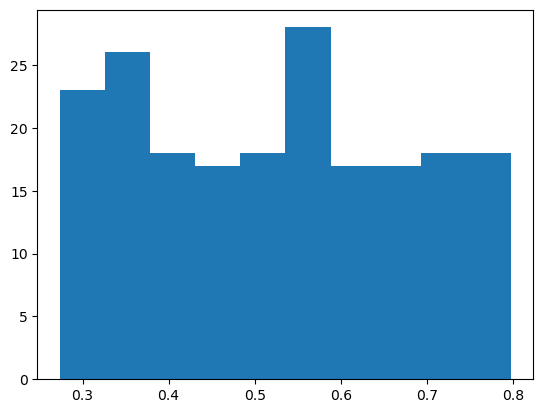

In [16]:
plt.hist(true_vals)

(array([23., 26., 18., 17., 18., 28., 17., 17., 18., 18.]),
 array([-1.10486006, -0.89537365, -0.68588724, -0.47640083, -0.26691441,
        -0.057428  ,  0.15205841,  0.36154482,  0.57103124,  0.78051765,
         0.99000406]),
 <BarContainer object of 10 artists>)

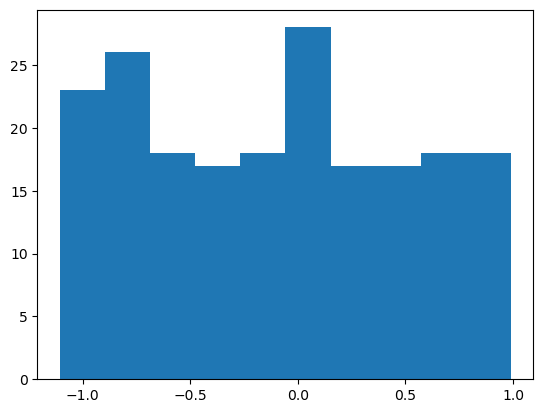

In [17]:
plt.hist(vals_norm)

In [18]:
params_ds.to_netcdf('/glade/work/linnia/CLM6-PPE/ctsm53065_lhc/clm6lhc_01192025_v3.nc')

### Convert Wave1 params

In [2]:
ds_params_wave1 = xr.open_dataset('/glade/work/linnia/CLM6-PPE/ctsm53065_wave1/wave1_paramsets.nc')
ds_params_wave1 = ds_params_wave1.rename({'ensemble': 'ens'})

In [3]:
# Transform ds_params_wave1 to have param as a dimension (like ds_params_norm)
# Convert all parameter variables into a single DataArray with param dimension

# Get all data variables (parameter names)
param_vars = list(ds_params_wave1.data_vars)

# Convert to array - this stacks all variables along a new 'param' dimension
ds_params_wave1_transformed = ds_params_wave1[param_vars].to_array(dim='param', name='wave1_params')

# Reorder dimensions to match expected format: (ensemble/ens, param, pft)
# Check which dimension names are used
dims = list(ds_params_wave1_transformed.dims)
if 'ens' in dims:
    # Reorder to (ens, param, ...)
    dim_order = ['ens', 'param'] + [d for d in dims if d not in ['ens', 'param']]
    ds_params_wave1_transformed = ds_params_wave1_transformed.transpose(*dim_order)
else:
    # If no ensemble dimension, just ensure param is first
    dim_order = ['param'] + [d for d in dims if d != 'param']
    ds_params_wave1_transformed = ds_params_wave1_transformed.transpose(*dim_order)

ds_params_wave1_transformed.to_netcdf('/glade/work/linnia/CLM6-PPE/ctsm53065_wave1/ctsm53065_wave1_12032025.nc')

In [6]:
### Fix bgc_rf_s2s1
ds_params_wave1 = xr.open_dataset('/glade/work/linnia/CLM6-PPE/ctsm53065_wave1/ctsm53065_wave1_12032025.nc')
wave1_norm = ds_params_wave1.wave1_params.sel(param='RF_SS',pft=1).values

# convert wave1 to true vals
mini = 0.55
maxi = 0.8
true_vals = wave1_norm *(maxi-mini)+mini

mini = 0.2
maxi = 0.8
vals_norm = (true_vals-mini)/(maxi-mini)

for p in ds_params_wave1_transformed.pft.values:
    ds_params_wave1_transformed.loc[dict(param='RF_SS', pft=p)] = vals_norm


In [7]:
ds_params_wave1_transformed.isel(pft=slice(1,15)).to_netcdf('/glade/work/linnia/CLM6-PPE/ctsm53065_wave1/ctsm53065_wave1_12032025_v2.nc')

(array([28., 22., 14., 12., 14., 18., 24., 27., 20., 21.]),
 array([0.5502924 , 0.575055  , 0.59981761, 0.62458022, 0.64934283,
        0.67410544, 0.69886805, 0.72363066, 0.74839327, 0.77315587,
        0.79791848]),
 <BarContainer object of 10 artists>)

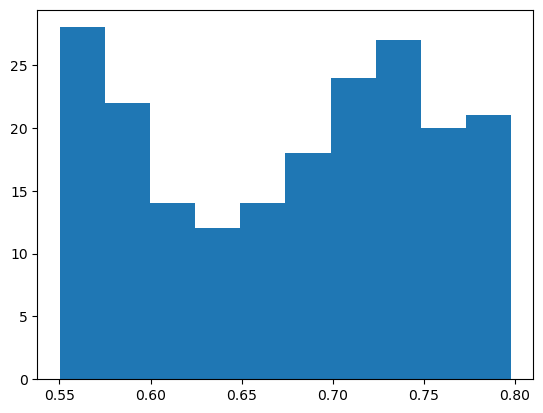

In [8]:
plt.hist(true_vals)

(array([28., 22., 14., 12., 14., 18., 24., 27., 20., 21.]),
 array([0.58382066, 0.62509167, 0.66636269, 0.7076337 , 0.74890472,
        0.79017573, 0.83144675, 0.87271776, 0.91398878, 0.95525979,
        0.9965308 ]),
 <BarContainer object of 10 artists>)

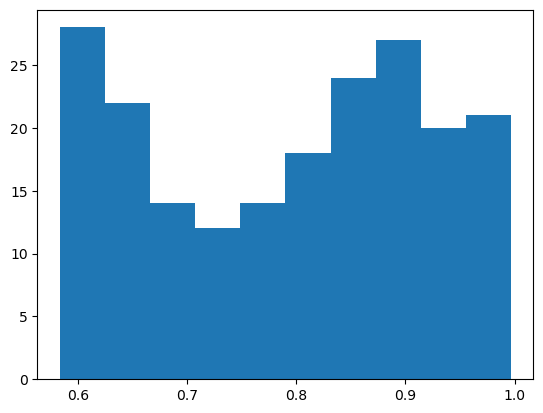

In [9]:
plt.hist(vals_norm)

### Wave2

In [19]:
ds_params_wave2 = xr.open_dataset('/glade/u/home/linnia/CLM6-PPE/clm6-hm/paramsets/wave2_paramsets.nc')

In [20]:
ds_topup = xr.open_dataset('/glade/u/home/linnia/CLM6-PPE/clm6-hm/paramsets/wave2_paramsets_topup.nc')

In [21]:
ds_params_wave2.isel(ens=145).jmaxb1.values

array(0.90819206)

In [22]:
ds_topup.jmaxb1.values

array([0.5737256])

In [23]:
ds_topup_single = ds_topup.isel(ens=0)

# Assign values into ds at ens=146
ds_params_wave2.loc[dict(ens=145)] = ds_topup_single

In [24]:
ds_params_wave2.jmaxb1.isel(ens=145).values

array(0.5737256)

In [25]:
# Transform ds_params_wave1 to have param as a dimension (like ds_params_norm)
# Convert all parameter variables into a single DataArray with param dimension

# Get all data variables (parameter names)
param_vars = list(ds_params_wave2.data_vars)

# Convert to array - this stacks all variables along a new 'param' dimension
ds_params_wave2_transformed = ds_params_wave2[param_vars].to_array(dim='param', name='wave2_params')

# Reorder dimensions to match expected format: (ensemble/ens, param, pft)
# Check which dimension names are used
dims = list(ds_params_wave2_transformed.dims)
if 'ens' in dims:
    # Reorder to (ens, param, ...)
    dim_order = ['ens', 'param'] + [d for d in dims if d not in ['ens', 'param']]
    ds_params_wave2_transformed = ds_params_wave2_transformed.transpose(*dim_order)
else:
    # If no ensemble dimension, just ensure param is first
    dim_order = ['param'] + [d for d in dims if d != 'param']
    ds_params_wave2_transformed = ds_params_wave2_transformed.transpose(*dim_order)

ds_params_wave2_transformed.isel(pft=slice(1,15)).to_netcdf('/glade/work/linnia/CLM6-PPE/ctsm53065_wave2/ctsm53065_wave2_12232025.nc')

In [21]:
### Fix bgc_rf_s2s1
wave2_norm = ds_params_wave2_transformed.sel(param='RF_SS',pft=1).values

# convert wave1 to true vals
mini = 0.55
maxi = 0.8
true_vals = wave2_norm *(maxi-mini)+mini

mini = 0.2
maxi = 0.8
vals_norm = (true_vals-mini)/(maxi-mini)

for p in ds_params_wave2_transformed.pft.values:
    ds_params_wave2_transformed.loc[dict(param='RF_SS', pft=p)] = vals_norm


In [22]:
ds_params_wave2_transformed.isel(pft=slice(1,15)).to_netcdf('/glade/work/linnia/CLM6-PPE/ctsm53065_wave2/ctsm53065_wave2_12232025_v2.nc')

### Wave3

In [3]:
ds_params_wave3 = xr.open_dataset('/glade/u/home/linnia/CLM6-PPE/clm6-hm/paramsets/wave3_paramsets.nc')

In [4]:
ds_topup = xr.open_dataset('/glade/u/home/linnia/CLM6-PPE/clm6-hm/paramsets/wave3_paramsets_topup.nc')

In [5]:
# wave30025
ds_topup_single = ds_topup.isel(ens=0)
ds_params_wave3.loc[dict(ens=24)] = ds_topup_single
# wave30078
ds_topup_single = ds_topup.isel(ens=1)
ds_params_wave3.loc[dict(ens=77)] = ds_topup_single

In [6]:
# Transform ds_params_wave1 to have param as a dimension (like ds_params_norm)
# Convert all parameter variables into a single DataArray with param dimension

# Get all data variables (parameter names)
param_vars = list(ds_params_wave3.data_vars)

# Convert to array - this stacks all variables along a new 'param' dimension
ds_params_wave3_transformed = ds_params_wave3[param_vars].to_array(dim='param', name='wave3_params')

# Reorder dimensions to match expected format: (ensemble/ens, param, pft)
# Check which dimension names are used
dims = list(ds_params_wave3_transformed.dims)
if 'ens' in dims:
    # Reorder to (ens, param, ...)
    dim_order = ['ens', 'param'] + [d for d in dims if d not in ['ens', 'param']]
    ds_params_wave3_transformed = ds_params_wave3_transformed.transpose(*dim_order)
else:
    # If no ensemble dimension, just ensure param is first
    dim_order = ['param'] + [d for d in dims if d != 'param']
    ds_params_wave3_transformed = ds_params_wave3_transformed.transpose(*dim_order)



In [8]:
### Fix bgc_rf_s2s1
wave3_norm = ds_params_wave3_transformed.sel(param='RF_SS',pft=1).values

# convert to true vals
mini = 0.55
maxi = 0.8
true_vals = wave3_norm *(maxi-mini)+mini

mini = 0.2
maxi = 0.8
vals_norm = (true_vals-mini)/(maxi-mini)

for p in ds_params_wave3_transformed.pft.values:
    ds_params_wave3_transformed.loc[dict(param='RF_SS', pft=p)] = vals_norm


In [7]:
ds_params_wave3_transformed.isel(pft=slice(1,15)).to_netcdf('/glade/work/linnia/CLM6-PPE/ctsm53065_wave3/ctsm53065_wave3_01012026.nc')

### Wave4

In [2]:
ds_params_wave4 = xr.open_dataset('/glade/u/home/linnia/CLM6-PPE/clm6-hm/paramsets/wave4_paramsets.nc')

In [3]:
ds_topup = xr.open_dataset('/glade/u/home/linnia/CLM6-PPE/clm6-hm/paramsets/wave4_paramsets_topup.nc')

In [5]:
# wave30142
ds_topup_single = ds_topup.isel(ens=0)
ds_params_wave4.loc[dict(ens=141)] = ds_topup_single
# wave30159
ds_topup_single = ds_topup.isel(ens=1)
ds_params_wave4.loc[dict(ens=158)] = ds_topup_single

In [6]:
# Transform ds_params_wave1 to have param as a dimension (like ds_params_norm)
# Convert all parameter variables into a single DataArray with param dimension

# Get all data variables (parameter names)
param_vars = list(ds_params_wave4.data_vars)

# Convert to array - this stacks all variables along a new 'param' dimension
ds_params_wave4_transformed = ds_params_wave4[param_vars].to_array(dim='param', name='wave4_params')

# Reorder dimensions to match expected format: (ensemble/ens, param, pft)
# Check which dimension names are used
dims = list(ds_params_wave4_transformed.dims)
if 'ens' in dims:
    # Reorder to (ens, param, ...)
    dim_order = ['ens', 'param'] + [d for d in dims if d not in ['ens', 'param']]
    ds_params_wave4_transformed = ds_params_wave4_transformed.transpose(*dim_order)
else:
    # If no ensemble dimension, just ensure param is first
    dim_order = ['param'] + [d for d in dims if d != 'param']
    ds_params_wave4_transformed = ds_params_wave4_transformed.transpose(*dim_order)



In [7]:
### Fix bgc_rf_s2s1
wave4_norm = ds_params_wave4_transformed.sel(param='RF_SS',pft=1).values

# convert to true vals
mini = 0.55
maxi = 0.8
true_vals = wave4_norm *(maxi-mini)+mini

mini = 0.2
maxi = 0.8
vals_norm = (true_vals-mini)/(maxi-mini)

for p in ds_params_wave4_transformed.pft.values:
    ds_params_wave4_transformed.loc[dict(param='RF_SS', pft=p)] = vals_norm


In [9]:
ds_params_wave4_transformed.isel(pft=slice(1,15)).to_netcdf('/glade/work/linnia/CLM6-PPE/ctsm53065_wave4/ctsm53065_wave4_02042026.nc')

### HMC

In [3]:
ds_params_hmc = xr.open_dataset('/glade/u/home/linnia/CLM6-PPE/clm6-calibration/hmc_results/selected_posterior_subset.nc')

In [4]:
# Transform ds_params_wave1 to have param as a dimension (like ds_params_norm)
# Convert all parameter variables into a single DataArray with param dimension

# Get all data variables (parameter names)
param_vars = list(ds_params_hmc.data_vars)

# Convert to array - this stacks all variables along a new 'param' dimension
ds_params_hmc_transformed = ds_params_hmc[param_vars].to_array(dim='param', name='hmc_params')

# Reorder dimensions to match expected format: (ensemble/ens, param, pft)
# Check which dimension names are used
dims = list(ds_params_hmc_transformed.dims)
if 'ens' in dims:
    # Reorder to (ens, param, ...)
    dim_order = ['ens', 'param'] + [d for d in dims if d not in ['ens', 'param']]
    ds_params_hmc_transformed = ds_params_hmc_transformed.transpose(*dim_order)
else:
    # If no ensemble dimension, just ensure param is first
    dim_order = ['param'] + [d for d in dims if d != 'param']
    ds_params_hmc_transformed = ds_params_hmc_transformed.transpose(*dim_order)



In [5]:
### Fix bgc_rf_s2s1
hmc_norm = ds_params_hmc_transformed.sel(param='RF_SS',pft=1).values

# convert to true vals
mini = 0.55
maxi = 0.8
true_vals = hmc_norm *(maxi-mini)+mini

mini = 0.2
maxi = 0.8
vals_norm = (true_vals-mini)/(maxi-mini)

for p in ds_params_hmc_transformed.pft.values:
    ds_params_hmc_transformed.loc[dict(param='RF_SS', pft=p)] = vals_norm


In [6]:
ds_params_hmc_transformed.isel(pft=slice(1,15)).to_netcdf('/glade/work/linnia/CLM6-PPE/ctsm53065_hmc/ctsm53065_hmc_05042026.nc')